In [41]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


try:
    train_df = pd.read_csv('data/train.csv')
    test_df = pd.read_csv('data/test.csv')
    print('✅ Datasets loaded successfully!')
except FileNotFoundError:
    print('❌ Error: File not found. Please double-check the folder path and filenames.')


✅ Datasets loaded successfully!


In [42]:
def convert_df(df):
    df['Sex'] = df['Sex'].map({'male': 0, 'female': 1})
    df['Age'] = df['Age'].fillna(df['Age'].median())
    df["CabinClass"] = df["Cabin"].str[0].fillna("X")
    return df

train_df = convert_df(train_df)
test_df = convert_df(test_df)

#### Tree example:
```
tree = {
    "feature": "Pclass",
    "threshold": 2.5,
    "left": ...,
    "right": ...
}
```

In [43]:
class BinaryTree:

    def __init__(self):
        self.tree = {}

    def gini(self, p0, p1):
        sum = p0 + p1
        if sum == 0:
            return 0.0
        gini_impurity = 1 - (p0/sum)**2 - (p1/sum)**2
        return gini_impurity

    def split(self, df, label, threshold, exact=False):
        if exact:
            left = df[df[label] == threshold]
            right = df[df[label] != threshold]
        else:
            left = df[df[label] <= threshold]
            right = df[df[label] > threshold]
        return left, right

    def split_quality(self, df_left, df_right, target_label):
        sum_left = len(df_left)
        sum_right = len(df_right)
        sum = sum_left + sum_right

        left_counts = df_left[target_label].value_counts()
        right_counts = df_right[target_label].value_counts()

        gini_left = 0
        if len(left_counts) == 2:
            gini_left = self.gini(left_counts[0], left_counts[1])

        gini_right = 0
        if len(right_counts) == 2:
            gini_right = self.gini(right_counts[0], right_counts[1])

        weighted_gini = sum_left / sum * gini_left + sum_right / sum * gini_right
        return weighted_gini
    
    def best_threshold(self, df, label, exact=False):
        sorted_unique_values = df.sort_values(label)[label].unique().tolist()
        best_threshold = sorted_unique_values[0]
        best_q = 1
        for value in sorted_unique_values:
            left, right = self.split(df, label, value, exact)
            if len(left) != 0 and len(right) != 0:
                q = self.split_quality(left, right, 'Survived')
                if q < best_q:
                    best_q = q
                    best_threshold = value
        print(
            f"Label: {label}, "
            f"Best threshold: {best_threshold}, "
            f"Split_quality: {best_q}"
            )
        return best_threshold, best_q

    def all_threshold_qualities(self, df, label, exact=False):
        sorted_unique_values = df.sort_values(label)[label].unique().tolist()
        threshold_scores = []
        for value in sorted_unique_values:
            left, right = self.split(df, label, value, exact)
            if len(left) != 0 and len(right) != 0:
                q = self.split_quality(left, right, 'Survived')
                threshold_scores.append((value, q))
        return threshold_scores

    def best_label(self, df, labels):
        label_qualities = []
        for label, exact in labels.items():
            best_threshold, best_q = self.best_threshold(df, label, exact)
            label_qualities.append((label, best_threshold, best_q))

        if not label_qualities:
            raise ValueError("labels must contain at least one feature")

        best_label, best_threshold, best_score = min(
            label_qualities,
            key=lambda item: item[2]
        )

        print(
            f"Best label: {best_label}, "
            f"threshold: {best_threshold}, "
            f"split_quality: {best_score}"
        )

        return best_label, best_threshold, best_score 

    def construct_tree(self, df, labels, max_depth=3, depth=0):
        if df.empty:
            return {"prediction": 0}

        if df['Survived'].nunique() <= 1 or depth >= max_depth or not labels:
            mode = df['Survived'].mode()
            prediction = int(mode.iloc[0]) if not mode.empty else 0
            return {"prediction": prediction}

        best_label, best_threshold, _ = self.best_label(df, labels)
        exact = labels[best_label]
        left_df, right_df = self.split(df, best_label, best_threshold, exact)

        left_labels = labels.copy()
        right_labels = labels.copy()

        node = {
            "feature": best_label,
            "threshold": best_threshold,
            "exact": exact,
            "left": self.construct_tree(left_df, left_labels, max_depth=max_depth, depth=depth + 1),
            "right": self.construct_tree(right_df, right_labels, max_depth=max_depth, depth=depth + 1)
        }
        self.tree = node
        return node

    def prediction(self, row, tree=None):
        if tree is None:
            tree = self.tree

        if not tree:
            return 0

        if "prediction" in tree:
            return tree["prediction"]

        feature = tree["feature"]
        threshold = tree["threshold"]
        exact = tree.get("exact", False)
        value = row[feature]

        if exact:
            next_node = tree["left"] if value == threshold else tree["right"]
        else:
            next_node = tree["left"] if value <= threshold else tree["right"]

        return self.prediction(row, next_node)


In [44]:
binarytree = BinaryTree()
binarytree.best_threshold(train_df, 'Sex', False)
binarytree.best_threshold(train_df, 'Pclass', False)
binarytree.best_threshold(train_df, 'Age', False)

Label: Sex, Best threshold: 0, Split_quality: 0.3333650003885904
Label: Pclass, Best threshold: 2, Split_quality: 0.4238751054331502
Label: Age, Best threshold: 6.0, Split_quality: 0.46172983235602977


(6.0, 0.46172983235602977)

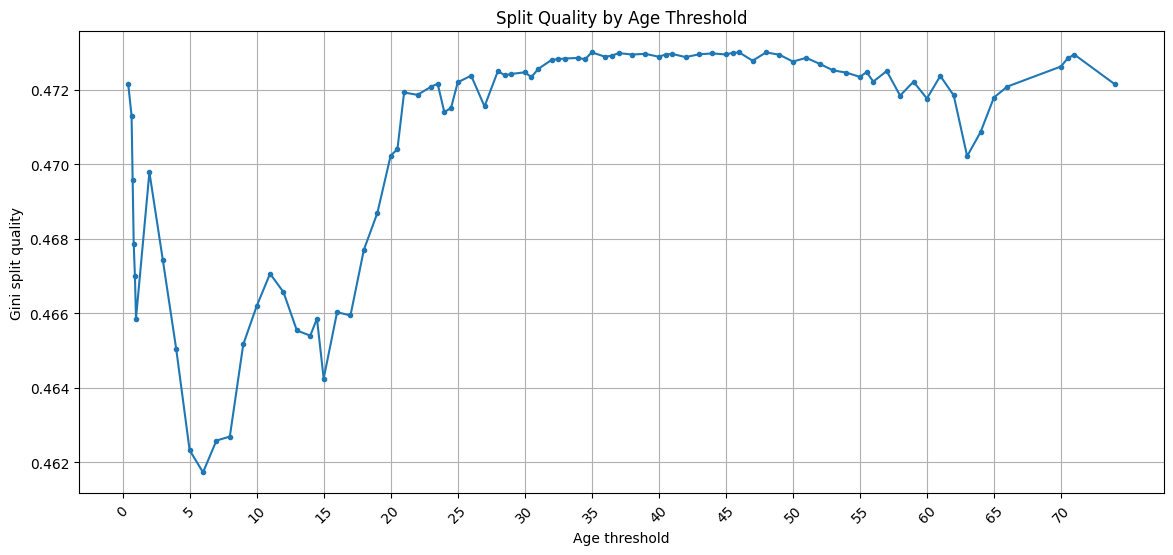

In [45]:
threshold_scores = binarytree.all_threshold_qualities(train_df, 'Age', False)

thresholds, qualities = zip(*threshold_scores)

plt.figure(figsize=(14, 6), dpi=100)
plt.plot(thresholds, qualities, marker='o', markersize=3)
plt.xticks(np.arange(int(min(thresholds)), int(max(thresholds)) + 1, 5), rotation=45)
plt.xlabel('Age threshold')
plt.ylabel('Gini split quality')
plt.title('Split Quality by Age Threshold')
plt.grid(True)
plt.show()

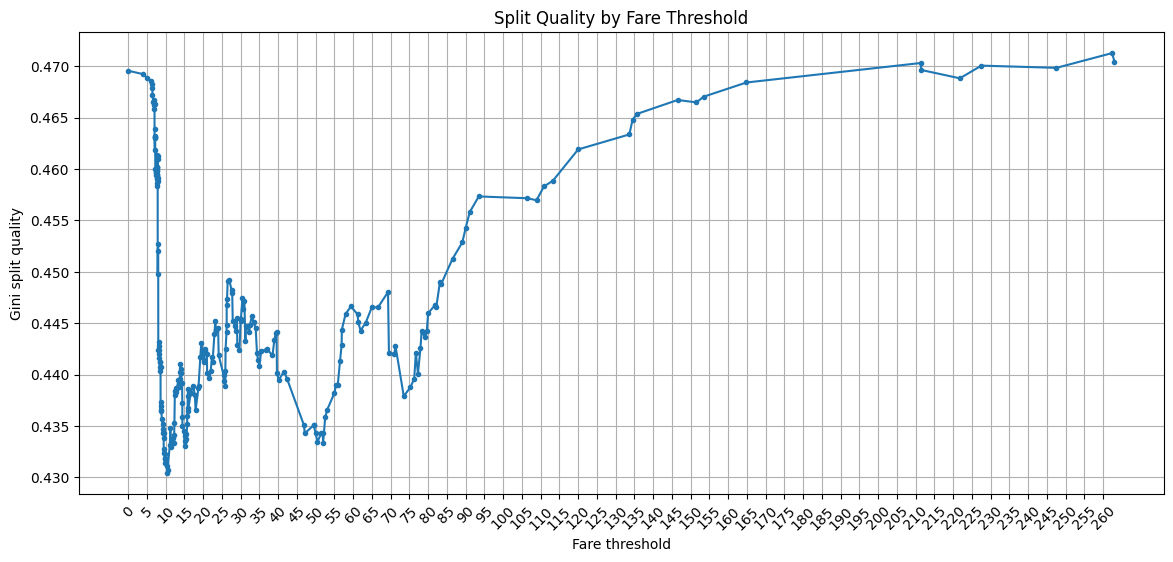

In [46]:
threshold_scores = binarytree.all_threshold_qualities(train_df, 'Fare', False)

thresholds, qualities = zip(*threshold_scores)

plt.figure(figsize=(14, 6), dpi=100)
plt.plot(thresholds, qualities, marker='o', markersize=3)
plt.xticks(np.arange(int(min(thresholds)), int(max(thresholds)) + 1, 5), rotation=45)
plt.xlabel('Fare threshold')
plt.ylabel('Gini split quality')
plt.title('Split Quality by Fare Threshold')
plt.grid(True)
plt.show()

In [47]:
labels = {
    'Sex': False,
    'Pclass': False,
    'Age': False,
    #'CabinClass': True,
    'Fare': False,
    # 'SibSp': False,
    # 'Parch': False,
    # 'Embarked': True
}

binarytree.best_label(train_df, labels)

Label: Sex, Best threshold: 0, Split_quality: 0.3333650003885904
Label: Pclass, Best threshold: 2, Split_quality: 0.4238751054331502
Label: Age, Best threshold: 6.0, Split_quality: 0.46172983235602977
Label: Fare, Best threshold: 10.4625, Split_quality: 0.4304294062855048
Best label: Sex, threshold: 0, split_quality: 0.3333650003885904


('Sex', 0, 0.3333650003885904)

In [48]:
binarytree.construct_tree(train_df, labels, max_depth=3)

Label: Sex, Best threshold: 0, Split_quality: 0.3333650003885904
Label: Pclass, Best threshold: 2, Split_quality: 0.4238751054331502
Label: Age, Best threshold: 6.0, Split_quality: 0.46172983235602977
Label: Fare, Best threshold: 10.4625, Split_quality: 0.4304294062855048
Best label: Sex, threshold: 0, split_quality: 0.3333650003885904
Label: Sex, Best threshold: 0, Split_quality: 1
Label: Pclass, Best threshold: 1, Split_quality: 0.28907952007648013
Label: Age, Best threshold: 6.0, Split_quality: 0.2866315031815327
Label: Fare, Best threshold: 26.25, Split_quality: 0.2887371038812159
Best label: Age, threshold: 6.0, split_quality: 0.2866315031815327
Label: Sex, Best threshold: 0, Split_quality: 1
Label: Pclass, Best threshold: 2, Split_quality: 0.2857142857142858
Label: Age, Best threshold: 0.92, Split_quality: 0.38596491228070173
Label: Fare, Best threshold: 20.575, Split_quality: 0.3333333333333333
Best label: Pclass, threshold: 2, split_quality: 0.2857142857142858
Label: Sex, Best 

{'feature': 'Sex',
 'threshold': 0,
 'exact': False,
 'left': {'feature': 'Age',
  'threshold': 6.0,
  'exact': False,
  'left': {'feature': 'Pclass',
   'threshold': 2,
   'exact': False,
   'left': {'prediction': 1},
   'right': {'prediction': 0}},
  'right': {'feature': 'Pclass',
   'threshold': 1,
   'exact': False,
   'left': {'prediction': 0},
   'right': {'prediction': 0}}},
 'right': {'feature': 'Pclass',
  'threshold': 2,
  'exact': False,
  'left': {'feature': 'Age',
   'threshold': 2.0,
   'exact': False,
   'left': {'prediction': 0},
   'right': {'prediction': 1}},
  'right': {'feature': 'Fare',
   'threshold': 23.25,
   'exact': False,
   'left': {'prediction': 1},
   'right': {'prediction': 0}}}}

In [49]:
binarytree.prediction(train_df.iloc[0])

0

In [50]:
submission_df = pd.DataFrame({
    "PassengerId": [],
    "Survived": []
})

for _, row in test_df.iterrows():
    survived = binarytree.prediction(row)

    submission_df.loc[len(submission_df)] = {
        "PassengerId": row['PassengerId'],
        "Survived": survived
    }

submission_df.to_csv("data/submission.csv", index=False)

## Kaggle evaluation
- Accuracy: 0.77990
- Position: 3387/11351